# 3. Logistic regression: adjusted associations

Notebook 2 compared heart disease prevalence across one variable at a time. Those comparisons are tangled together: smokers are more often men, diabetics are older, and age is strongly tied to heart disease. This notebook estimates each association **while holding the other variables fixed**, using logistic regression.

The results are odds ratios (OR). An OR of 1.5 for smoking means: comparing two respondents who are identical on every other variable in the model, the one with a smoking history has 1.5 times the odds of reporting heart disease.

> **These are associations, not causal effects.** The data is a single cross-sectional survey. It cannot show what would happen to someone's risk if they changed a behaviour. Section 3.2 explains why this matters more than usual here.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from cvd import data, features, models, plots, stats
from cvd.data import LABELS, TARGET
from cvd.features import FEATURES_ALL, FEATURES_HEALTH_STATUS, FEATURES_LIFESTYLE

plots.set_style()
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 200)

df = data.load_clean()
print(f"{len(df):,} respondents, heart disease prevalence {df[TARGET].mean():.2%}")

308,774 respondents, heart disease prevalence 8.09%


## 3.1 How the predictors are coded

- **Categorical variables** are compared against a reference level: "No" for the yes/no variables, Female, age 18-24, "Excellent" general health, and a checkup "Within the past year" (by far the largest checkup group).
- **Numeric variables** are scaled so that one unit is a meaningful step: BMI per 5 kg/m², alcohol per 10 drinking days a month, and the food variables per 30 times a month, i.e. one additional time per day.
- **Height and weight are excluded.** BMI is computed from them (notebook 1), and height mainly stands in for sex (notebook 2).

The coding lives in `cvd.features.logit_design_matrix`.

In [2]:
design_all = features.logit_design_matrix(df, FEATURES_ALL)
print(f"Design matrix for the full model: {design_all.shape[0]:,} rows x {design_all.shape[1]} columns (including the intercept)")
print("Example columns:", ", ".join(design_all.columns[[1, 2, 14, 15, 17, 21]]))

Design matrix for the full model: 308,774 rows x 36 columns (including the intercept)
Example columns: sex: Male, age_category: 25-29, BMI (per +5 kg/m²), smoking_history: Yes, Alcohol (per +10 drinking days/month), general_health: Poor


## 3.2 Which variables should be in the model? Reverse causation and leakage

The survey asks about the present. Heart disease, once diagnosed, changes several of the other answers:

| Variable | Why it may be a *consequence* of heart disease |
|---|---|
| Self-rated general health | People rate their health as poor *because* they have heart disease |
| Last routine checkup | Cardiac patients see doctors regularly |
| Diabetes, arthritis, depression, cancers | Partly shared causes (age, lifestyle), partly diagnosed more often in people who are already under medical care |
| Alcohol, exercise, diet, BMI | Also not immune: people are told to change these after a diagnosis |

This creates two different problems:

1. **For explanation:** adjusting for a consequence of the outcome, or for a step on the path between a behaviour and the outcome, distorts the behaviour's coefficient. If inactivity leads to poor health and poor health goes with heart disease, then holding "general health" fixed removes most of the association of inactivity.
2. **For prediction:** a model that leans on "my health is poor" and "I see my doctor often" is partly detecting people who already know they are ill. That is *leakage* if the aim is to flag risk from lifestyle alone.

No choice of variables fixes this with cross-sectional data. The honest approach is to fit both versions and compare them:

- **Model A, all predictors:** lifestyle, demographics and health status (16 variables).
- **Model B, lifestyle and demographics only:** sex, age, BMI, smoking, exercise, alcohol and diet (9 variables).

In [3]:
print("Model B (lifestyle and demographics):", ", ".join(FEATURES_LIFESTYLE))
print("Added in Model A (health status):    ", ", ".join(FEATURES_HEALTH_STATUS))

fits = {
    "A: all predictors": models.fit_logit(df, FEATURES_ALL),
    "B: lifestyle + demographics": models.fit_logit(df, FEATURES_LIFESTYLE),
    "Age and sex only": models.fit_logit(df, ["age_category", "sex"]),
}
fit_summary = models.logit_fit_summary(fits)
fit_summary

Model B (lifestyle and demographics): sex, age_category, bmi, smoking_history, exercise, alcohol_consumption, fruit_consumption, green_vegetables_consumption, fried_potato_consumption
Added in Model A (health status):     general_health, checkup, diabetes, arthritis, depression, skin_cancer, other_cancer


,n_obs,n_params,log_likelihood,aic,mcfadden_r2,converged
A: all predictors,308774,36,"-68,491.631","137,055.262",0.210,True
B: lifestyle + demographics,308774,21,"-73,804.950","147,651.900",0.149,True
Age and sex only,308774,14,"-76,014.176","152,056.353",0.124,True


In [4]:
lr = models.likelihood_ratio_test(fits["B: lifestyle + demographics"], fits["A: all predictors"])
print(f"Likelihood-ratio test, B nested in A: statistic = {lr['lr_stat']:,.0f} on {lr['dof']} df, p = {stats.format_p(lr['p_value'])}")
r2 = fit_summary["mcfadden_r2"]
print(f"McFadden pseudo-R²: age and sex only {r2['Age and sex only']:.3f}, model B {r2['B: lifestyle + demographics']:.3f}, model A {r2['A: all predictors']:.3f}")

Likelihood-ratio test, B nested in A: statistic = 10,627 on 15 df, p = < 1e-300
McFadden pseudo-R²: age and sex only 0.124, model B 0.149, model A 0.210


All three models converged. Two things stand out:

- **Age and sex alone account for most of what Model B explains** (pseudo-R² 0.124 of 0.149). The seven lifestyle variables add comparatively little.
- **The health-status variables add a lot** (pseudo-R² rises to 0.210). That is the gain that may partly be leakage.

McFadden's pseudo-R² is not a share of variance and values around 0.2 are normal for a good logistic model, so these numbers are for comparing the models with each other. Predictive performance is measured properly, on held-out data, in notebook 4.

## 3.3 Model B: lifestyle and demographics

In [5]:
or_a = models.odds_ratio_table(fits["A: all predictors"])
or_b = models.odds_ratio_table(fits["B: lifestyle + demographics"])

or_b.assign(p_value=or_b["p_value"].map(stats.format_p))

,odds_ratio,ci_low,ci_high,p_value
sex: Male,2.007,1.950,2.065,< 1e-300
age_category: 25-29,1.307,0.993,1.721,0.056
age_category: 30-34,1.864,1.457,2.385,7.1e-07
age_category: 35-39,2.204,1.741,2.790,5.0e-11
age_category: 40-44,3.282,2.622,4.108,3.3e-25
age_category: 45-49,5.335,4.293,6.631,1.7e-51
age_category: 50-54,7.970,6.450,9.849,2.4e-82
age_category: 55-59,12.247,9.943,15.085,1.1e-122
age_category: 60-64,16.290,13.246,20.033,4.5e-154
age_category: 65-69,21.070,17.144,25.894,1.4e-184


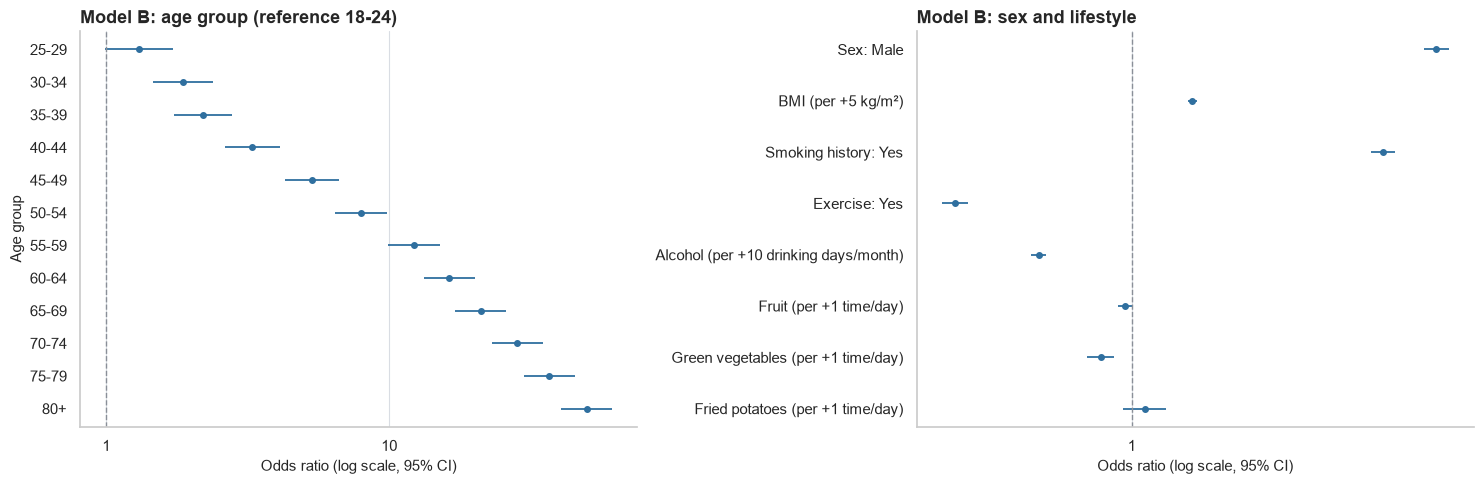

In [6]:
is_age = or_b.index.str.startswith("age_category")
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1]})
plots.forest_plot(or_b[is_age].rename(index=lambda s: s.replace("age_category: ", "")), axes[0], "Model B: age group (reference 18-24)")
axes[0].set_ylabel("Age group")
plots.forest_plot(or_b[~is_age].rename(index=lambda s: s.replace("smoking_history", "Smoking history").replace("exercise", "Exercise").replace("sex", "Sex")), axes[1], "Model B: sex and lifestyle")
fig.tight_layout()
plt.show()

**Reading Model B.**

- **Age** dwarfs everything. The odds rise in every step, to about 50 times the odds of an 18-24-year-old at 80+. (With an 8% outcome, odds ratios run higher than prevalence ratios; the raw prevalence ratio in notebook 2 was 43.)
- **Sex:** men have twice the odds of women of the same age and lifestyle (OR 2.0). The unadjusted odds ratio is 1.71 (section 3.5), so the raw comparison understated the gap.
- **Smoking history:** OR 1.78, the strongest behavioural association.
- **Exercise:** people who exercised in the past month have a third lower odds (OR 0.67).
- **BMI:** each additional 5 kg/m² goes with 15% higher odds (OR 1.15).
- **Alcohol:** each additional 10 drinking days a month goes with 19% *lower* odds (OR 0.81). This is the reverse-causation candidate: non-drinkers include people who stopped for health reasons.
- **Diet:** green vegetables once more per day goes with 7% lower odds (OR 0.93). Fruit and fried potatoes show no association; both intervals include 1.

## 3.4 Model A: all predictors

In [7]:
or_a.assign(p_value=or_a["p_value"].map(stats.format_p))

,odds_ratio,ci_low,ci_high,p_value
sex: Male,2.138,2.074,2.203,< 1e-300
age_category: 25-29,1.359,1.032,1.790,0.029
age_category: 30-34,1.891,1.477,2.421,4.3e-07
age_category: 35-39,2.126,1.678,2.693,4.1e-10
age_category: 40-44,2.956,2.359,3.703,4.5e-21
age_category: 45-49,4.317,3.470,5.371,2.5e-39
age_category: 50-54,5.921,4.786,7.326,2.8e-60
age_category: 55-59,8.322,6.747,10.265,3.3e-87
age_category: 60-64,10.584,8.593,13.035,3.6e-109
age_category: 65-69,13.509,10.974,16.630,4.0e-133


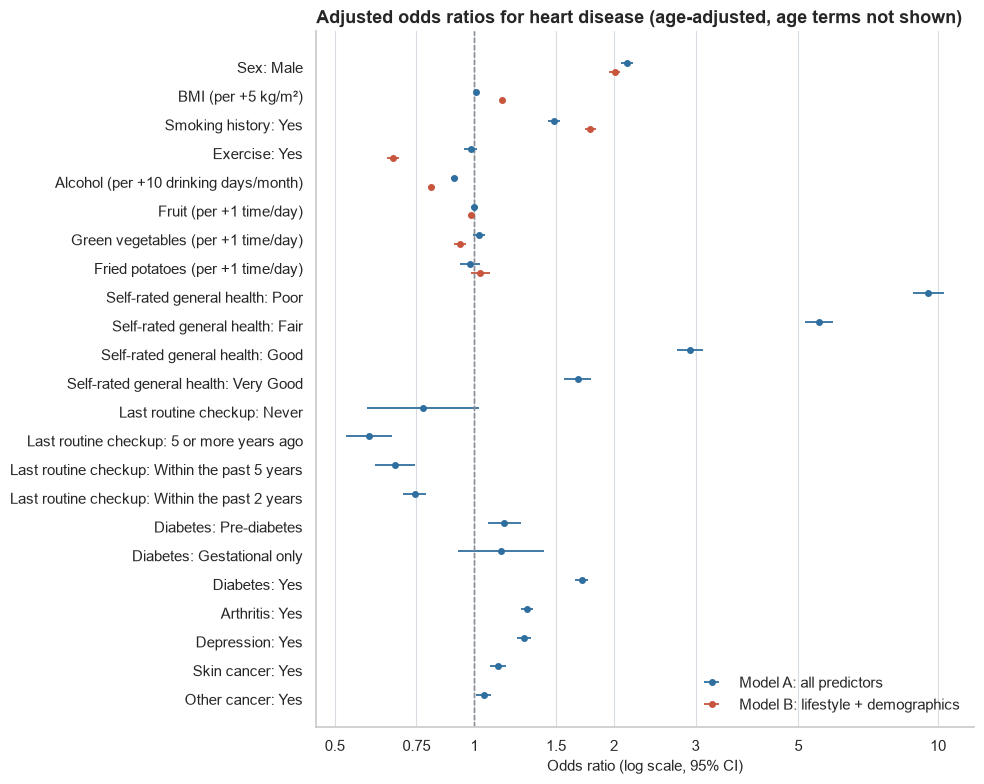

In [8]:
non_age_terms = or_a.index[~or_a.index.str.startswith("age_category")]


def pretty(term: str) -> str:
    name, _, level = term.partition(": ")
    return f"{LABELS[name].replace(' in past 30 days', '')}: {level}" if level else term


comparison = or_a.loc[non_age_terms].rename(index=pretty)
comparison_b = or_b.reindex(non_age_terms).rename(index=pretty)

fig, ax = plt.subplots(figsize=(10, 8))
plots.forest_plot(comparison, ax, "Adjusted odds ratios for heart disease (age-adjusted, age terms not shown)", color=plots.BLUE, label="Model A: all predictors", offset=0.15)
plots.forest_plot(comparison_b, ax, "Adjusted odds ratios for heart disease (age-adjusted, age terms not shown)", color=plots.RED, label="Model B: lifestyle + demographics", offset=-0.15)
ax.legend(loc="lower right")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 5, 10])
ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "3", "5", "10"])

fig.tight_layout()
plots.save_figure(fig, "odds_ratios_forest")
plt.show()

**Reading Model A, in plain language** (each statement compares respondents who are alike on all other variables in the model):

- **Self-rated general health** is the strongest non-age term. Someone rating their health "Poor" has 9.5 times the odds of someone rating it "Excellent", and the odds fall in order through Fair (5.5), Good (2.9) and Very Good (1.7).
- **Sex:** men have 2.1 times the odds of women.
- **Diabetes:** 1.7 times the odds. Pre-diabetes is a much weaker 1.16.
- **Smoking history:** 1.48 times the odds.
- **Arthritis and depression:** each about 1.3 times the odds.
- **Checkup:** every less-recent category has *lower* odds than "within the past year" (OR 0.59 to 0.78). Seeing a doctor recently marks people who are already patients.
- **Skin cancer and other cancer:** small (1.12 and 1.05). Their raw prevalence ratios of about 2.2 in notebook 2 were almost entirely age.
- **Age:** still a steep gradient, up to about 30 times the odds at 80+.

## 3.5 What changes between the models

The table puts three estimates side by side for the lifestyle variables: unadjusted (one predictor at a time), Model B and Model A.

In [9]:
lifestyle_terms = or_b.index[~is_age]
unadjusted = models.unadjusted_odds_ratios(df, [f for f in FEATURES_LIFESTYLE if f != "age_category"])
three_way = pd.DataFrame(
    {
        "unadjusted": unadjusted.loc[lifestyle_terms, "odds_ratio"],
        "model_B": or_b.loc[lifestyle_terms, "odds_ratio"],
        "B_ci": [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(or_b.loc[lifestyle_terms, "ci_low"], or_b.loc[lifestyle_terms, "ci_high"], strict=True)],
        "model_A": or_a.loc[lifestyle_terms, "odds_ratio"],
        "A_ci": [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(or_a.loc[lifestyle_terms, "ci_low"], or_a.loc[lifestyle_terms, "ci_high"], strict=True)],
    }
)
three_way

,unadjusted,model_B,B_ci,model_A,A_ci
sex: Male,1.713,2.007,1.95 to 2.06,2.138,2.07 to 2.20
BMI (per +5 kg/m²),1.116,1.149,1.14 to 1.16,1.010,1.00 to 1.02
smoking_history: Yes,2.196,1.777,1.73 to 1.83,1.484,1.44 to 1.53
exercise: Yes,0.480,0.668,0.65 to 0.69,0.981,0.95 to 1.01
Alcohol (per +10 drinking days/month),0.831,0.808,0.79 to 0.82,0.905,0.89 to 0.92
Fruit (per +1 time/day),0.912,0.986,0.97 to 1.00,1.000,0.98 to 1.02
Green vegetables (per +1 time/day),0.823,0.932,0.90 to 0.96,1.024,0.99 to 1.06
Fried potatoes (per +1 time/day),0.880,1.030,0.98 to 1.08,0.979,0.93 to 1.03


**Three patterns.**

1. **Adjusting for age removes spurious "effects".** Unadjusted, eating fried potatoes daily looks protective (OR 0.88) and so does fruit (0.91). With age and sex held fixed (Model B) both are indistinguishable from 1. The raw associations existed because younger people eat more fried potatoes and have less heart disease.
2. **Adding health status absorbs the lifestyle associations.** From Model B to Model A, exercise goes from OR 0.67 to 0.98 and BMI from 1.15 to 1.01; both lose their association entirely. Smoking weakens from 1.78 to 1.48 and alcohol from 0.81 to 0.90.
3. **This does not mean exercise and BMI are irrelevant.** Inactive and heavier respondents report worse general health and more diabetes. Once those are in the model, there is little left for exercise and BMI to explain. If poor health is partly a *result* of inactivity, Model A has adjusted away the very pathway of interest; if inactivity is partly a *result* of heart disease, Model B overstates it. The data cannot tell these apart.

The practical reading: Model B gives the upper range of the lifestyle associations, Model A the lower range, and neither is a causal estimate.

## 3.6 Checks

### Are the numeric terms really linear?

The model assumes the log-odds change by the same amount for every 5 BMI points or 10 drinking days. Notebook 1 suggested otherwise (underweight respondents and non-drinkers had raised prevalence). Refitting Model B with BMI and alcohol as categories tests this.

In [10]:
check = df.assign(
    bmi_cat=pd.cut(df["bmi"], [0, 18.5, 25, 30, 35, 40, 200], labels=["<18.5", "18.5-25", "25-30", "30-35", "35-40", "40+"], right=False),
    alcohol_cat=pd.cut(df["alcohol_consumption"], [0, 1, 5, 15, 30, 31], labels=["0", "1-4", "5-14", "15-29", "30"], right=False),
)
categorical_fit = smf.logit(
    "heart_disease ~ C(bmi_cat, Treatment('18.5-25')) + C(alcohol_cat, Treatment('1-4')) + C(sex) + C(age_category)"
    " + C(smoking_history) + C(exercise) + fruit_consumption + green_vegetables_consumption + fried_potato_consumption",
    data=check.astype({"age_category": "object"}),
).fit(disp=False)
cat_or = pd.DataFrame(
    {"odds_ratio": np.exp(categorical_fit.params), "ci_low": np.exp(categorical_fit.conf_int()[0]), "ci_high": np.exp(categorical_fit.conf_int()[1])}
)
cat_or = cat_or[cat_or.index.str.contains("bmi_cat|alcohol_cat")]
cat_or.index = [
    ("BMI " if "bmi_cat" in term else "Alcohol days ") + term.split("[T.")[1].rstrip("]") for term in cat_or.index
]
print("Reference levels: BMI 18.5-25 and 1-4 drinking days per month")
print(f"AIC with linear BMI and alcohol: {fits['B: lifestyle + demographics'].aic:,.0f}   with categories: {categorical_fit.aic:,.0f}")
cat_or

Reference levels: BMI 18.5-25 and 1-4 drinking days per month
AIC with linear BMI and alcohol: 147,652   with categories: 147,256


,odds_ratio,ci_low,ci_high
BMI <18.5,1.175,1.042,1.325
BMI 25-30,1.149,1.108,1.192
BMI 30-35,1.418,1.361,1.477
BMI 35-40,1.610,1.527,1.697
BMI 40+,1.879,1.767,1.999
Alcohol days 0,1.355,1.308,1.403
Alcohol days 5-14,0.815,0.773,0.860
Alcohol days 15-29,0.769,0.726,0.815
Alcohol days 30,0.797,0.742,0.857


**Takeaway.** Both relationships are non-linear, and the categorical version fits better (lower AIC).

- **BMI:** the odds rise steadily above the normal range, to about 1.9 times at BMI 40+, but underweight respondents also have raised odds (1.18). A single linear term averages over this.
- **Alcohol:** there is a step, then a plateau. Compared with light drinkers (1-4 days), non-drinkers have 1.36 times the odds; from 5 days upward the odds ratio sits at about 0.8 and does not fall further, so daily drinkers look no different from people who drink 5-14 days. A large step at zero followed by a flat line is not a dose-response pattern. It is what one would expect if non-drinkers include people who stopped for health reasons, although this data cannot confirm that.

The linear terms are kept in Models A and B because they are easier to read, with this caveat attached. The gradient-boosted model in notebook 4 learns such shapes by itself.

### Do the implausible body measurements matter?

In [11]:
flagged = data.add_quality_flags(df)
refit = models.odds_ratio_table(models.fit_logit(flagged[~flagged["flag_implausible"]], FEATURES_ALL))
relative_change = (refit["odds_ratio"] / or_a["odds_ratio"] - 1).abs()
print(f"Rows flagged as implausible and excluded in the refit: {int(flagged['flag_implausible'].sum())}")
print(f"Largest relative change in any Model A odds ratio: {relative_change.max():.2%} ({relative_change.idxmax()})")
print(f"BMI odds ratio: {or_a.loc['BMI (per +5 kg/m²)', 'odds_ratio']:.4f} with all rows, {refit.loc['BMI (per +5 kg/m²)', 'odds_ratio']:.4f} without flagged rows")

Rows flagged as implausible and excluded in the refit: 234
Largest relative change in any Model A odds ratio: 1.12% (age_category: 35-39)
BMI odds ratio: 1.0102 with all rows, 1.0119 without flagged rows


**Takeaway.** Dropping the 234 flagged rows changes no odds ratio by more than about 1%. Keeping them (the policy from notebook 1) has no effect on the conclusions.

### Other assumptions

- **Independence:** one row per respondent. BRFSS samples within states, so responses are mildly clustered and the confidence intervals are somewhat too narrow. The file has no state or weight column, so this cannot be corrected.
- **Collinearity:** notebook 1 found no strongly correlated pair among the predictors used here (largest rank correlation 0.31), and no coefficient shows the inflated standard errors that collinearity would cause.
- **Sample size:** the smallest category (checkup "Never", 1,407 respondents) has the widest interval, and it is the only checkup level whose interval includes 1.

## Summary

- **Age and sex carry most of the explainable variation.** At 80+ the odds of reported heart disease are 30 to 50 times those at 18-24 depending on the model, and men have about twice the odds of women.
- **Among behaviours, smoking history is the most robust:** OR 1.78 adjusted for age, sex and lifestyle, and still 1.48 after adding health status.
- **Exercise and BMI are associated with heart disease only until health status is controlled** (exercise OR 0.67 → 0.98, BMI 1.15 → 1.01), which is the pattern expected if they act through, or are affected by, general health.
- **Diet variables show little:** only green vegetables has an association in Model B (OR 0.93), and it vanishes in Model A.
- **Three results are best explained by reverse causation, not benefit or harm:** lower odds with more alcohol, higher odds with a recent checkup, and the dominant role of self-rated health.
- None of these is a causal effect. They describe who reports heart disease in a 2021 telephone survey.

Next: [notebook 4](04_predictive_model.ipynb) asks how well heart disease can be predicted, with and without the health-status variables.